# 13 — Real events: GW150914, GW151012, GW151226 through the project's detectors

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What it does.** Applies the *unchanged* pipeline (whitening with the median-Welch PSD of the chunk, 1 s window, sine-Gaussian bank and IMRPhenomD bank, per-detector empirical p-values on the notebook-09 backgrounds, Fisher combination with the 15 ms arrival-time gate) to three real O1 binary black holes, in H1 and L1 (extension 8). It reports the detection statistic, the best-fit total mass and merger time, the single-detector p-values and a coincident false-alarm probability, and where the event ranks among the other ≈4000 windows of its own chunk.

**What it does not do.** The events were *not* used to tune anything. The IMR bank covers total masses 30–100 M☉ (detector frame) with non-spinning templates, so GW151226 (≈22 M☉ in the source frame, a long inspiral) lies partly outside it and is expected to be weak: that is a result, not a failure. Where the GWOSC file contains NaN (out-of-science gaps: 189 s of L1 around GW150914, most of the H1 file of GW151226) only the common NaN-free stretch around the event is used (3907 s, 4096 s, 540 s). The coincident FAP is the independent-detector formula (1+S)e^{−S}, which ignores the time-gate and is therefore conservative; it is not an astrophysical false-alarm rate and the CNN is not used here.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import imr_tools as it
import gwosc_tools as g
g.style()
EV = g.load_json("events_chunks.json"); DET = ("H1", "L1"); GATE = 0.015; TPOS = 0.65     # event placed at 0.65 s of its window
def valid_span(ev):
    # GWOSC files contain NaN where a detector was out of science mode: keep the common NaN-free stretch around the event (whole seconds)
    ie = int((ev["gps"] - ev["gps_start"]) * g.FS_RAW); lo, hi = 0, CHUNK_N
    for d in DET:
        bad = np.where(np.isnan(np.load(os.path.join(g.CACHE, "raw", ev["files"][d]))))[0]
        if (bad < ie).any(): lo = max(lo, bad[bad < ie].max() + 1)
        if (bad > ie).any(): hi = min(hi, bad[bad > ie].min())
    lo = int(np.ceil(lo / g.FS_RAW)) * g.FS_RAW; hi = int(np.floor(hi / g.FS_RAW)) * g.FS_RAW
    return lo, hi
CHUNK_N = 4096 * g.FS_RAW
SPAN = {e["event"]: valid_span(e) for e in EV}
print({k: ((b - a) / g.FS_RAW, a / g.FS_RAW) for k, (a, b) in SPAN.items()}, "(seconds of common clean data, offset in the file)")
def whiten(ev, det):
    lo, hi = SPAN[ev["event"]]
    x = np.load(os.path.join(g.CACHE, "raw", ev["files"][det]))[lo:hi]; v, f, S = g.whiten_chunk(x); return v, g.psd_1hz(f, S)
W = {(e["event"], d): whiten(e, d) for e in EV for d in DET}
BANK = {(k, e["event"], d): (g.SGBank if k == "sg" else it.IMRBank)(W[(e["event"], d)][1]) for e in EV for d in DET for k in ("sg", "imr")}
print({k: len(v[0]) for k, v in W.items()})

{'GW150914': (3907.0, 189.0), 'GW151012': (4096.0, 0.0), 'GW151226': (540.0, 3556.0)} (seconds of common clean data, offset in the file)


{('GW150914', 'H1'): 4000768, ('GW150914', 'L1'): 4000768, ('GW151012', 'H1'): 4194304, ('GW151012', 'L1'): 4194304, ('GW151226', 'H1'): 552960, ('GW151226', 'L1'): 552960}


## 1. Single-detector backgrounds (the four background chunks of notebook 09)

In [2]:
CHK = g.load_json("coinc_chunks.json"); BKG_IDX = [0, 1, 3, 4]
fn = os.path.join(g.CACHE, "bkg13.npz")
if os.path.exists(fn):
    z = np.load(fn); BKG = {tuple(k.split("|")): z[k] for k in z.files}
else:
    BKG = {}
    for d in DET:
        for k in BKG_IDX:
            c = g.load_coinc_chunk(k, d)
            for kind, B in (("sg", g.SGBank(c["S1"])), ("imr", it.IMRBank(c["S1"]))):
                BKG.setdefault((kind, d), []).append(B.scan(g.to_bins(c["v"]))["rho2"])
    BKG = {k: np.concatenate(v) for k, v in BKG.items()}
    np.savez_compressed(fn, **{"|".join(k): v for k, v in BKG.items()})
print({k: len(v) for k, v in BKG.items()})
def pval(kind, d, x):
    B = np.sort(BKG[(kind, d)]); return (len(B) - np.searchsorted(B, x, side="left") + 1.0) / (len(B) + 1.0)

{('sg', 'H1'): 16224, ('imr', 'H1'): 16224, ('sg', 'L1'): 16224, ('imr', 'L1'): 16224}


## 2. The three events

In [3]:
rows = []; TRACE = {}
for e in EV:
    ev = e["event"]; res = {}
    for d in DET:
        v, S1 = W[(ev, d)]
        i0 = int(round((e["gps"] - e["gps_start"] - SPAN[ev][0] / g.FS_RAW) * g.FS - TPOS * g.NWIN)); win = v[i0:i0 + g.NWIN]; TRACE[(ev, d)] = (win, i0)
        for kind in ("sg", "imr"):
            o = BANK[(kind, ev, d)].scan(g.to_bins(win[None]))
            # local distribution: all other non-overlapping windows of the chunk (event +-10 s removed)
            allw = g.make_windows(v); gstart = g.TRIM * g.FS
            keep = np.abs((gstart + np.arange(len(allw)) * g.NWIN + g.NWIN / 2) - (i0 + TPOS * g.NWIN)) > 10 * g.FS
            loc = BANK[(kind, ev, d)].scan(g.to_bins(allw[keep]))["rho2"]
            res[(kind, d)] = dict(rho2=float(o["rho2"][0]), tau=float(o["tau"][0]), par=(float(o["f0"][0]), float(o["Q"][0])),
                                  p_bkg=float(pval(kind, d, o["rho2"][0])), rank_local=int((loc > o["rho2"][0]).sum() + 1), n_local=int(keep.sum()))
    for kind in ("sg", "imr"):
        h, l = res[(kind, "H1")], res[(kind, "L1")]
        Sc = -np.log(h["p_bkg"]) - np.log(l["p_bkg"]); dt = h["tau"] - l["tau"]; ok = abs(dt) <= GATE
        rows.append(dict(event=ev, bank=kind, rho_H=np.sqrt(h["rho2"]), rho_L=np.sqrt(l["rho2"]), rho_net=np.sqrt(h["rho2"] + l["rho2"]),
                         tau_H=h["tau"], dt_HL_ms=1e3 * dt, gate_ok=ok, M_H=h["par"][0] if kind == "imr" else np.nan, M_L=l["par"][0] if kind == "imr" else np.nan,
                         p_H=h["p_bkg"], p_L=l["p_bkg"], S=Sc, FAP_coinc=(1 + Sc) * np.exp(-Sc) if ok else 1.0,
                         rank_H=h["rank_local"], rank_L=l["rank_local"], n_local=h["n_local"]))
R = pd.DataFrame(rows); R.round(4)

,event,bank,rho_H,rho_L,rho_net,tau_H,dt_HL_ms,gate_ok,M_H,M_L,p_H,p_L,S,FAP_coinc,rank_H,rank_L,n_local
0,GW150914,sg,12.0880,8.7638,14.9307,0.6719,6.8359,True,NaN,NaN,0.0024,0.0010,12.9525,0.0000,3,2,3847
1,GW150914,imr,19.1664,13.3420,23.3530,0.6719,5.8594,True,72.0,72.0,0.0014,0.0004,14.5058,0.0000,1,2,3847
2,GW151012,sg,4.5334,4.0780,6.0977,0.6729,5.8594,True,NaN,NaN,0.1885,0.6724,2.0653,0.3886,962,2821,4036
3,GW151012,imr,6.5368,6.3872,9.1392,0.6914,-0.9766,True,42.0,42.0,0.0049,0.0039,10.8760,0.0002,9,3,4036
4,GW151226,sg,4.8147,5.5962,7.3823,0.3604,-320.3125,False,NaN,NaN,0.0697,0.0312,6.1292,1.0000,26,3,480
5,GW151226,imr,4.7103,4.8076,6.7305,0.5303,-153.3203,False,35.0,50.0,0.0941,0.1059,4.6093,1.0000,42,25,480


Reading the table: `rho_*` are the square roots of the maximum of ρ² over the bank (matched-filter SNR, not the optimal SNR of the catalogue); `p_*` are empirical p-values on 16 224 background windows of notebook 09 (floor 6·10⁻⁵); `S` is the Fisher statistic; `FAP_coinc` uses (1+S)e^{−S} and is set to 1 if the arrival times differ by more than 15 ms; `rank_*` is the position among the other windows of the same chunk (1 = loudest).

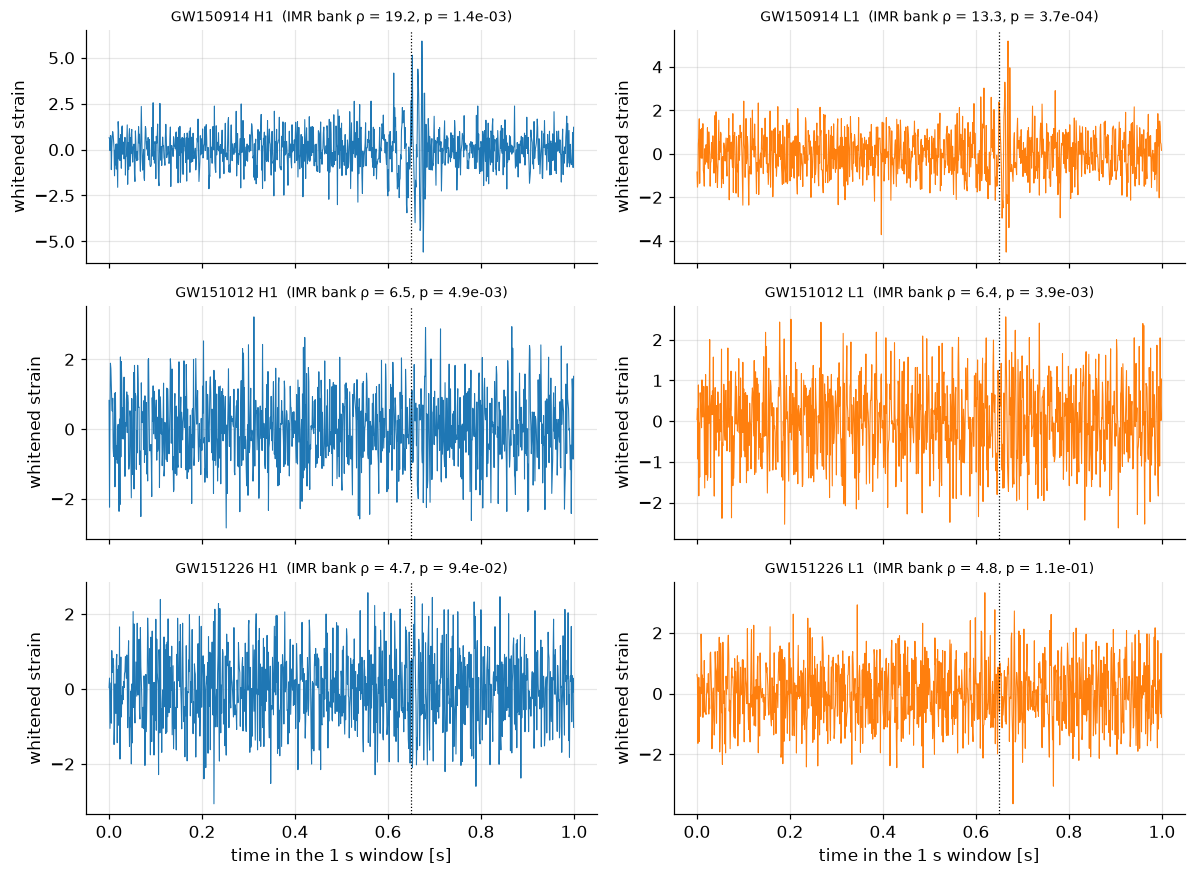

In [4]:
fig, ax = plt.subplots(len(EV), 2, figsize=(11, 2.7 * len(EV)), sharex=True)
t = (np.arange(g.NWIN) / g.FS)
for r, e in enumerate(EV):
    for c, d in enumerate(DET):
        win, i0 = TRACE[(e["event"], d)]; a = ax[r, c]
        a.plot(t, win, color=g.COLORS[d], lw=.7); a.axvline(TPOS, color="k", ls=":", lw=.8)
        row = R[(R.event == e["event"]) & (R.bank == "imr")].iloc[0]
        a.set_title(f"{e['event']} {d}  (IMR bank ρ = {row['rho_' + d[0]]:.1f}, p = {row['p_' + d[0]]:.1e})", fontsize=9); a.set_ylabel("whitened strain")
for a in ax[-1]: a.set_xlabel("time in the 1 s window [s]")
fig.tight_layout(); g.savefig(fig, "fig13_real_events"); plt.show()
g.save_json(dict(events=R.to_dict("records")), "13_summary.json")

## Output and next step

`results/13_summary.json`, `figures/fig13_real_events`, `results/events_chunks.json` (raw strain in `cache/raw/`, not tracked; regenerate with `python download_events.py`). Next: mini continuous search over hours of data with trigger clustering and a candidate list (extension 9).